# 1

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
df=pd.read_csv('us-shein-automotive-4110.csv')
#Escolhidos: automotive e toys-and-games.

# 2
- Primeiro, irei diagnosticar e tratar us-shein-automotive, após isso, toys-and-games.
- Pergunta de negócio: Produtos mais caros dão mais receita que baratos?

In [2]:
df

,goods-title-link--jump,goods-title-link--jump href,price,discount,selling_proposition,goods-title-link
0,"1pc/2PCS Car Cup Coaster, Bling Cup Holder Ins...",https://us.shein.com/1pc-2PCS-Car-Cup-Coaster-...,$0.68,-60%,NaN,NaN
1,Jesus The Way Truth Life Sticker For Car Windo...,https://us.shein.com/Jesus-The-Way-Truth-Life-...,$1.60,-20%,500+ sold recently,NaN
2,2PC Car Rearview Mirror Rain Eyebrow And Rain ...,https://us.shein.com/2PC-Car-Rearview-Mirror-R...,$1.60,NaN,200+ sold recently,NaN
3,"2pcs Car Rearview Mirror Rainproof Film, High-...",https://us.shein.com/2pcs-Car-Rearview-Mirror-...,$0.93,-34%,200+ sold recently,NaN
4,2pcs Multifunctional Car Hook,https://us.shein.com/2pcs-Multifunctional-Car-...,$1.12,-20%,1.9k+ sold recently,NaN
...,...,...,...,...,...,...
4104,NaN,NaN,$18.50,NaN,NaN,2 Pcs 3 Lens 4 Lens Super Bright Light Motorcy...
4105,NaN,NaN,$21.00,NaN,NaN,680 Car Fastener Clips Auto Body Push Retainer...
4106,NaN,NaN,$20.33,-25%,NaN,"Cargo Liner For SUV Dog, Rear Seat Hanging Car..."
4107,NaN,NaN,$17.40,NaN,40+ sold recently,Motorcycle Cover Universal Waterproof Accessor...


- Muitos valores nulos em goods-title-link--jump ,goods-title-link--jump href e goods-title-link
- Price,discount e price_proposition não está em formato correto para análise de dados


In [3]:
df.info()
#Todos os tipos, incluindo os que deveriam ser numéricos são string

<class 'pandas.DataFrame'>
RangeIndex: 4109 entries, 0 to 4108
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   goods-title-link--jump       40 non-null     str  
 1   goods-title-link--jump href  40 non-null     str  
 2   price                        4109 non-null   str  
 3   discount                     1373 non-null   str  
 4   selling_proposition          2874 non-null   str  
 5   goods-title-link             4069 non-null   str  
dtypes: str(6)
memory usage: 192.7 KB


In [4]:
df
#Já nessa pequena análise, consegue-se ver que há varios NaN

,goods-title-link--jump,goods-title-link--jump href,price,discount,selling_proposition,goods-title-link
0,"1pc/2PCS Car Cup Coaster, Bling Cup Holder Ins...",https://us.shein.com/1pc-2PCS-Car-Cup-Coaster-...,$0.68,-60%,NaN,NaN
1,Jesus The Way Truth Life Sticker For Car Windo...,https://us.shein.com/Jesus-The-Way-Truth-Life-...,$1.60,-20%,500+ sold recently,NaN
2,2PC Car Rearview Mirror Rain Eyebrow And Rain ...,https://us.shein.com/2PC-Car-Rearview-Mirror-R...,$1.60,NaN,200+ sold recently,NaN
3,"2pcs Car Rearview Mirror Rainproof Film, High-...",https://us.shein.com/2pcs-Car-Rearview-Mirror-...,$0.93,-34%,200+ sold recently,NaN
4,2pcs Multifunctional Car Hook,https://us.shein.com/2pcs-Multifunctional-Car-...,$1.12,-20%,1.9k+ sold recently,NaN
...,...,...,...,...,...,...
4104,NaN,NaN,$18.50,NaN,NaN,2 Pcs 3 Lens 4 Lens Super Bright Light Motorcy...
4105,NaN,NaN,$21.00,NaN,NaN,680 Car Fastener Clips Auto Body Push Retainer...
4106,NaN,NaN,$20.33,-25%,NaN,"Cargo Liner For SUV Dog, Rear Seat Hanging Car..."
4107,NaN,NaN,$17.40,NaN,40+ sold recently,Motorcycle Cover Universal Waterproof Accessor...


In [5]:
df.isna().sum()

goods-title-link--jump         4069
goods-title-link--jump href    4069
price                             0
discount                       2736
selling_proposition            1235
goods-title-link                 40
dtype: int64

In [6]:
df.duplicated().sum()
#Possui 179 linhas duplicadas, 
#que auxilia na limpeza, já que pode-se deletar essas linhas sem perdas de dados.

np.int64(179)

# 3
- Começo do pipeline

In [7]:
df_limpo=df.copy()
df_limpo=df_limpo.drop_duplicates()
df_limpo.info()

<class 'pandas.DataFrame'>
Index: 3930 entries, 0 to 4108
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   goods-title-link--jump       40 non-null     str  
 1   goods-title-link--jump href  40 non-null     str  
 2   price                        3930 non-null   str  
 3   discount                     1301 non-null   str  
 4   selling_proposition          2767 non-null   str  
 5   goods-title-link             3890 non-null   str  
dtypes: str(6)
memory usage: 214.9 KB


In [8]:
df_limpo['discount'].isna().sum()
#Pode-se ver que discount possui uma grande quantidade de valores nulos,
#que podem ser substituídos por 0 (já que ambos representam a ausência de desconto)
#Também irei transformar o formato -X% para apenas X, pois porcentagem de desconto já está inferido.

np.int64(2629)

In [9]:
df_limpo['discount']=df_limpo['discount'].replace(np.nan,0)
df_limpo['discount']=df_limpo['discount'].str.replace(r'[%-]','',regex=True).fillna(0)
df_limpo['discount']=df_limpo['discount'].astype(np.int64)

In [10]:
df_limpo['price']
# Price é str, com cifrão de dólar, mas seria melhor se ele fosse apenas float64.

0        $0.68
1        $1.60
2        $1.60
3        $0.93
4        $1.12
         ...  
4094    $24.58
4095    $72.99
4096    $33.75
4097    $38.87
4108    $59.99
Name: price, Length: 3930, dtype: str

In [11]:
df_limpo['price']=df_limpo['price'].str.replace('$','')
df_limpo['price']=df_limpo['price'].astype(np.float64)

In [12]:
df_limpo['price']

0        0.68
1        1.60
2        1.60
3        0.93
4        1.12
        ...  
4094    24.58
4095    72.99
4096    33.75
4097    38.87
4108    59.99
Name: price, Length: 3930, dtype: float64

In [13]:
df_limpo
#Percebe-se que goods-title-link--jump e goods-title-link são os mesmo dados,
#portanto, pode-se substituir o link --jump e deletá-lo, também colocar os links em href, baseado no goods-title-link.

,goods-title-link--jump,goods-title-link--jump href,price,discount,selling_proposition,goods-title-link
0,"1pc/2PCS Car Cup Coaster, Bling Cup Holder Ins...",https://us.shein.com/1pc-2PCS-Car-Cup-Coaster-...,0.68,60,NaN,NaN
1,Jesus The Way Truth Life Sticker For Car Windo...,https://us.shein.com/Jesus-The-Way-Truth-Life-...,1.60,20,500+ sold recently,NaN
2,2PC Car Rearview Mirror Rain Eyebrow And Rain ...,https://us.shein.com/2PC-Car-Rearview-Mirror-R...,1.60,0,200+ sold recently,NaN
3,"2pcs Car Rearview Mirror Rainproof Film, High-...",https://us.shein.com/2pcs-Car-Rearview-Mirror-...,0.93,34,200+ sold recently,NaN
4,2pcs Multifunctional Car Hook,https://us.shein.com/2pcs-Multifunctional-Car-...,1.12,20,1.9k+ sold recently,NaN
...,...,...,...,...,...,...
4094,NaN,NaN,24.58,0,NaN,Unbeatablesale 8 Lbs Smoke Hickory Wood Blocks
4095,NaN,NaN,72.99,72,NaN,VIVOHOME 1100 LBS Motorcycle Lift Scissor Jack...
4096,NaN,NaN,33.75,0,NaN,Unbeatablesale Arctic Warrior Tip Up
4097,NaN,NaN,38.87,0,NaN,Unbeatablesale 17972 4.5 Gal Oval Drain Pan


In [14]:
df_limpo['goods-title-link']=df_limpo['goods-title-link'].fillna(df_limpo['goods-title-link--jump'])
df_limpo=df_limpo.drop(columns=['goods-title-link--jump'])

In [15]:
df_limpo['goods-title-link--jump href']
#Devido a complexidade do link, não é possível acrescentar novos links por meio dos títulos.
# Portanto,a melhor ação seria dar drop na coluna.

0       https://us.shein.com/1pc-2PCS-Car-Cup-Coaster-...
1       https://us.shein.com/Jesus-The-Way-Truth-Life-...
2       https://us.shein.com/2PC-Car-Rearview-Mirror-R...
3       https://us.shein.com/2pcs-Car-Rearview-Mirror-...
4       https://us.shein.com/2pcs-Multifunctional-Car-...
                              ...                        
4094                                                  NaN
4095                                                  NaN
4096                                                  NaN
4097                                                  NaN
4108                                                  NaN
Name: goods-title-link--jump href, Length: 3930, dtype: str

In [16]:
df_limpo=df_limpo.drop(columns=['goods-title-link--jump href'])

In [17]:
df_limpo
#Por último, podemos ver o selling_proposition, que possui valores NaN, e valores str que poderiam ser int.

,price,discount,selling_proposition,goods-title-link
0,0.68,60,NaN,"1pc/2PCS Car Cup Coaster, Bling Cup Holder Ins..."
1,1.60,20,500+ sold recently,Jesus The Way Truth Life Sticker For Car Windo...
2,1.60,0,200+ sold recently,2PC Car Rearview Mirror Rain Eyebrow And Rain ...
3,0.93,34,200+ sold recently,"2pcs Car Rearview Mirror Rainproof Film, High-..."
4,1.12,20,1.9k+ sold recently,2pcs Multifunctional Car Hook
...,...,...,...,...
4094,24.58,0,NaN,Unbeatablesale 8 Lbs Smoke Hickory Wood Blocks
4095,72.99,72,NaN,VIVOHOME 1100 LBS Motorcycle Lift Scissor Jack...
4096,33.75,0,NaN,Unbeatablesale Arctic Warrior Tip Up
4097,38.87,0,NaN,Unbeatablesale 17972 4.5 Gal Oval Drain Pan


In [18]:
df_limpo['selling_proposition'].unique()
#Pode-se ver que é apenas X sold recently, que pode ser substítuido apenas por X (ou 0 em casos de NaN)

<StringArray>
[                  nan,  '500+ sold recently',  '200+ sold recently',
 '1.9k+ sold recently',   '30+ sold recently', '3.2k+ sold recently',
  '800+ sold recently',  '100+ sold recently',  '400+ sold recently',
  '600+ sold recently',   '70+ sold recently',  '300+ sold recently',
  '700+ sold recently', '2.0k+ sold recently', '1.3k+ sold recently',
 '1.4k+ sold recently',   '40+ sold recently', '4.7k+ sold recently',
   '20+ sold recently', '1.6k+ sold recently', '2.5k+ sold recently',
 '3.9k+ sold recently', '3.7k+ sold recently',   '80+ sold recently',
   '10+ sold recently', '2.8k+ sold recently',  '900+ sold recently',
   '50+ sold recently', '1.1k+ sold recently', '5.2k+ sold recently',
 '1.2k+ sold recently', '2.9k+ sold recently', '2.1k+ sold recently',
 '1.8k+ sold recently', '1.7k+ sold recently',   '90+ sold recently',
   '60+ sold recently', '1.0k+ sold recently', '4.5k+ sold recently',
 '2.3k+ sold recently', '1.5k+ sold recently', '5.0k+ sold recently',
 '3.3k

In [19]:
def converter_vendas(texto):
    if pd.isna(texto):
        return 0
    texto = str(texto).replace('+ sold recently', '').strip()
    if 'k' in texto:
        texto = texto.replace('k', '')
        if '.' in texto:
            texto = texto.replace('.', '')
            return int(texto) * 100
        elif ',' in texto:
            texto = texto.replace(',', '.')
            return int(float(texto) * 1000)
        else:
            return int(texto) * 1000
    else:
        texto = texto.replace('.', '').replace(',', '')
        return int(texto) if texto.isdigit() else 0

df_limpo['selling_proposition'] = df_limpo['selling_proposition'].apply(converter_vendas)
df_limpo['selling_proposition'] = df_limpo['selling_proposition'].astype(np.int64)

# 4
- Criação de coluna `revenue`, que responde à pergunta de negócio.

In [20]:
df_limpo['revenue'] = df_limpo['selling_proposition'] * df_limpo['price'] * (1 - df_limpo['discount'] / 100)

<Axes: xlabel='price', ylabel='revenue'>

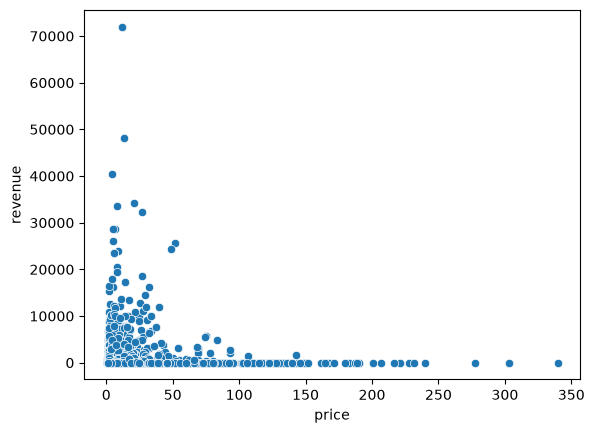

In [22]:
sns.scatterplot(df_limpo,x='price',y='revenue')
#Aqui, podemos ver outliers em selling_proposition (que venderam mais de 6 mil unidades), 
#e que eles tendem a ser itens baratos.

# 5
- Criação de funções reutilizáveis para o pipeline


In [24]:
def limpar_selling_prop(df):
    df = df.copy()
    df['selling_proposition'] = df['selling_proposition'].apply(converter_vendas)
    df['selling_proposition'] = df['selling_proposition'].astype(np.int64)
    return df

In [25]:
def limpar_preco(df):
    df['price']=df['price'].str.replace('$','')
    df['price']=df['price'].astype(np.float64)
    return df

In [26]:
def limpar_desconto(df):
    df['discount']=df['discount'].replace(np.nan,0)
    df['discount']=df['discount'].str.replace(r'[%-]','',regex=True).fillna(0)
    df['discount']=df['discount'].astype(np.int64)
    return df

In [27]:
def criar_revenue(df):
    df['revenue'] = df['selling_proposition'] * df['price'] * (1 - df['discount'] / 100)
    return df

In [28]:
df2=pd.read_csv('us-shein-toys_and_games-3577.csv')
df2

,rank-title,rank-sub,price,selling_proposition,discount,goods-title-link
0,#6 Best Sellers,in Kids Drawing & Painting Supplies,$2.90,NaN,NaN,NaN
1,NaN,NaN,$2.40,600+ sold recently,NaN,NaN
2,NaN,NaN,$3.80,1.2k+ sold recently,NaN,NaN
3,#2 Best Sellers,in Musical Instruments & Accessories,$1.20,NaN,NaN,NaN
4,NaN,NaN,$2.31,500+ sold recently,-54%,NaN
...,...,...,...,...,...,...
3571,NaN,NaN,$45.32,NaN,NaN,Unbeatablesale Jammin Pro My Gold Handheld Mic...
3572,NaN,NaN,$79.27,NaN,NaN,Unbeatablesale Wireless Handheld Microphone
3573,NaN,NaN,$3.00,100+ sold recently,NaN,"13pcs Birthday Decorative Balloon Set, Pink De..."
3574,NaN,NaN,$6.00,200+ sold recently,-8%,2 Pieces Medieval Black Costume Accessories Co...


- Será aplicada agora a limpeza.

In [29]:
df2_limpo=df2.copy()
df2_limpo=limpar_selling_prop(df2_limpo)
df2_limpo=limpar_desconto(df2_limpo)
df2_limpo=limpar_preco(df2_limpo)
df2_limpo=df2_limpo.drop_duplicates()
df2_limpo=criar_revenue(df2_limpo)

In [30]:
df2_limpo.info()
#Dá para ver que não há mais nulos em selling_proposition e discount,
#rank-title,sub e goods-title-link são strings portanto podem ser nulas.

<class 'pandas.DataFrame'>
Index: 3428 entries, 0 to 3575
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   rank-title           571 non-null    str    
 1   rank-sub             571 non-null    str    
 2   price                3428 non-null   float64
 3   selling_proposition  3428 non-null   int64  
 4   discount             3428 non-null   int64  
 5   goods-title-link     3416 non-null   str    
 6   revenue              3428 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 214.2 KB


In [31]:
df2_limpo.isna().sum()/3428 * 100
#Diminuição massiva de nulos em selling_proposition e discount, 
#mas pouquíssima diferença em rank-title e rank-sub.

rank-title             83.343057
rank-sub               83.343057
price                   0.000000
selling_proposition     0.000000
discount                0.000000
goods-title-link        0.350058
revenue                 0.000000
dtype: float64

In [32]:
df2.isna().sum()/3575*100

rank-title             83.720280
rank-sub               83.720280
price                   0.000000
selling_proposition    35.608392
discount               57.790210
goods-title-link        0.335664
dtype: float64

# 6
- Comparação antes e depois

In [33]:
df.info()
#Foram removidas 2 colunas: goods-title-link--jump e goods-title-link--jump href.

<class 'pandas.DataFrame'>
RangeIndex: 4109 entries, 0 to 4108
Data columns (total 6 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   goods-title-link--jump       40 non-null     str  
 1   goods-title-link--jump href  40 non-null     str  
 2   price                        4109 non-null   str  
 3   discount                     1373 non-null   str  
 4   selling_proposition          2874 non-null   str  
 5   goods-title-link             4069 non-null   str  
dtypes: str(6)
memory usage: 192.7 KB


In [34]:
df.isna().sum()/4108 * 100
#Mais de 99% de nulos no original.
#4109 é a quantidade total de linhas.

goods-title-link--jump         99.050633
goods-title-link--jump href    99.050633
price                           0.000000
discount                       66.601753
selling_proposition            30.063291
goods-title-link                0.973710
dtype: float64

In [35]:
df_limpo.info()
#Não ha mais nenhum valor nulo, sem nenhuma necessidade de escalonamento.

<class 'pandas.DataFrame'>
Index: 3930 entries, 0 to 4108
Data columns (total 5 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   price                3930 non-null   float64
 1   discount             3930 non-null   int64  
 2   selling_proposition  3930 non-null   int64  
 3   goods-title-link     3930 non-null   str    
 4   revenue              3930 non-null   float64
dtypes: float64(2), int64(2), str(1)
memory usage: 184.2 KB


In [36]:
df_limpo.isna().sum()/3930*100
#Nenhum nulo. Foram apenas retiradas linhas duplicadas.
# 3930 é a quantidade total de linhas.

price                  0.0
discount               0.0
selling_proposition    0.0
goods-title-link       0.0
revenue                0.0
dtype: float64

In [37]:
df2.info()

<class 'pandas.DataFrame'>
RangeIndex: 3576 entries, 0 to 3575
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype
---  ------               --------------  -----
 0   rank-title           583 non-null    str  
 1   rank-sub             583 non-null    str  
 2   price                3576 non-null   str  
 3   selling_proposition  2303 non-null   str  
 4   discount             1510 non-null   str  
 5   goods-title-link     3564 non-null   str  
dtypes: str(6)
memory usage: 167.8 KB


In [38]:
df2.isna().sum()/3575*100

rank-title             83.720280
rank-sub               83.720280
price                   0.000000
selling_proposition    35.608392
discount               57.790210
goods-title-link        0.335664
dtype: float64

In [39]:
df2_limpo.info()
#Dá para ver que não há mais nulos em selling_proposition e discount,
#rank-title,sub e goods-title-link são strings portanto podem ser nulas.

<class 'pandas.DataFrame'>
Index: 3428 entries, 0 to 3575
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   rank-title           571 non-null    str    
 1   rank-sub             571 non-null    str    
 2   price                3428 non-null   float64
 3   selling_proposition  3428 non-null   int64  
 4   discount             3428 non-null   int64  
 5   goods-title-link     3416 non-null   str    
 6   revenue              3428 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 214.2 KB


In [40]:
df2_limpo.isna().sum()/3428 * 100
#Diminuição massiva de nulos em selling_proposition e discount, 
#mas pouquíssima diferença em rank-title e rank-sub.

rank-title             83.343057
rank-sub               83.343057
price                   0.000000
selling_proposition     0.000000
discount                0.000000
goods-title-link        0.350058
revenue                 0.000000
dtype: float64

# 7
## Relatório:
- As principais decisões foram sobre o tipo de dado de cada coluna e a possibilidade de deixar todas não nulas, que é impossível com a df2, pois não possui dados o suficiente para inferir o restante das tabelas.
- Também as limpezas foram pensadas para a máxima regularização e entendimento do dado, comprovada pelos gráficos abaixo.

<Axes: ylabel='price'>

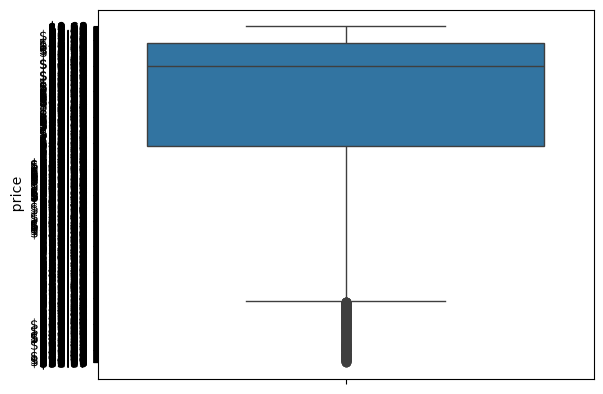

In [43]:
sns.boxplot(df['price'])
#Totalmente ilegível, por ser string com cifrão ao invés de int

<Axes: ylabel='price'>

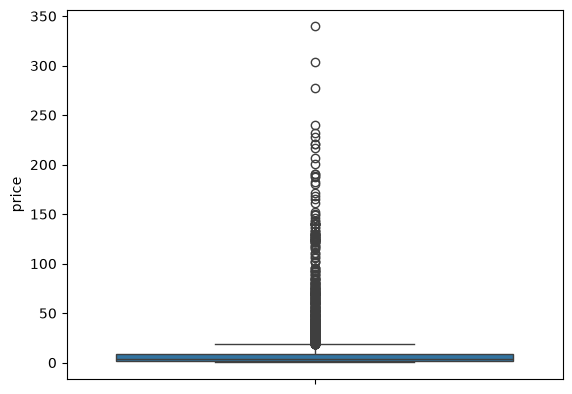

In [42]:
sns.boxplot(df_limpo['price'])
#Altamente legível.

<Axes: xlabel='price', ylabel='selling_proposition'>

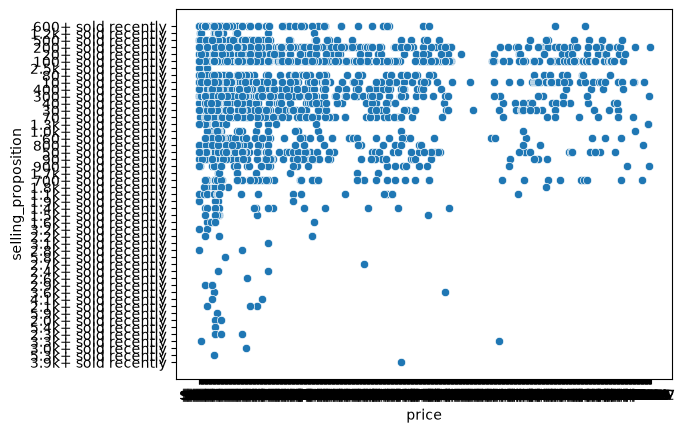

In [46]:
sns.scatterplot(df2,x='price',y='selling_proposition')

<Axes: xlabel='price', ylabel='selling_proposition'>

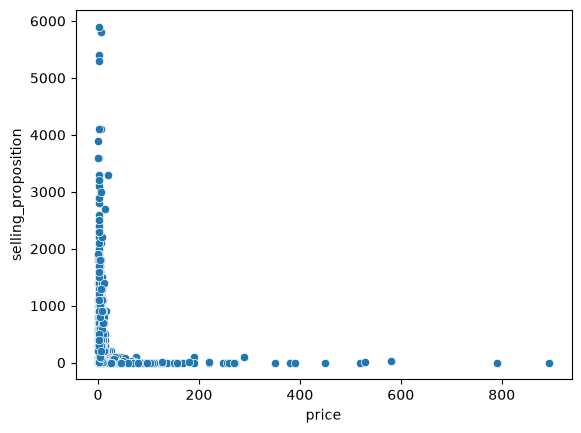

In [50]:
sns.scatterplot(df2_limpo,x='price',y='selling_proposition')

# Reflexão
- Sobre duplicatas de títulos, pois mesmo com vários NaN, poderiam passar despercebido pois são strings específicas, que não podem ser escalonadas, e pela quantidade, não podem ser removidas.
- Importa, pois se eu, por exemplo, não transformar uma coluna em int, e aplicar uma transformação ou operação que dependa que seja int, o código dará erro ou resultado inesperado.
- A limpeza de selling_proposition, se não fosse uma boa estimativa de vendas.